In [3]:
import csv

In [5]:
# Extraction of user information and communications from csv file
def csv_file(csv_file_path):
    edges = []
    with open (csv_file_path,encoding='utf-8-sig') as f:
        data = csv.reader(f)
        for row in data:
            edges.append(row)
            
    # pop source and target titles
    edges.pop(0)
    
    # convert list items from str to int
    edges = [[int(edge) for edge in sub]for sub in edges]
    return edges

In [7]:
edges = csv_file('PROJECT5.csv')
print(edges)

[[1, 2], [1, 3], [1, 5], [2, 3], [2, 4], [3, 5], [3, 1], [4, 6], [5, 4], [5, 10], [5, 11], [5, 2], [5, 3], [6, 8], [6, 5], [6, 3], [6, 10], [7, 6], [7, 9], [7, 1], [8, 5], [9, 11], [9, 3], [9, 6], [10, 1], [10, 11], [10, 7], [10, 4], [10, 3], [11, 10], [11, 9], [11, 7], [11, 5], [11, 4]]


In [81]:
class Graph:
    def __init__(self):
        self.node = set()
        self.edge = []
        self.adjacency = {}
        
    def add_node_list(self,edges):
        # Add all nodes from the edge list
        for edge in edges:
            if type(edge) is list:
                for i in edge :
                    self.node.add(i)
    
    def add_one_node(self,node):
        self.node.add(node)

    
    def build_edges(self,edges):
        # Convert edges to tuples and store them
        self.edge = [tuple(edge) for edge in edges]
        
    
    def add_one_edge(self,source,target):
        self.edge.append(tuple([source,target]))
        self.node.add(source)
        self.node.add(target)
    def add_adjacency_list(self,edges):
        
        # add vertices to adjacency dic
        for i in range(1,len(self.node)+1):
            self.adjacency[i] = []

        # Build the adjacency list from edges
        for edge in edges:
            vertex1,vertex2 = edge
            self.adjacency[vertex1].append(vertex2)
        
        
        # Social Media Communication Graph:
        print('\nSocial Media Communication Graph:\n')
        for vertex ,neighbors in self.adjacency.items():
            print(f"{vertex} -> {' '.join(map(str,neighbors))}")
            
    def number_of_users(self):
        return f' number of users:{len(self.node)}'

    def number_of_connections(self):
        return f' number of connections {len(self.edge)}'

    def neighbors(self,node):
        return self.adjacency[node]

    def direct_connection (self,source,target):
        return target in self.adjacency[source]

    def bfs (self,source,target=None):
        
        queue = []
        visited = set()
        traversed_graph = []
        #  Store each node's parent for path finding
        parent = {}
        
        queue.append(source)

        # The loop runs until the queue is not empty
        while len(queue)>0:
            
            # remove left most element from queue
            left_el = queue.pop(0)
            
            # traversing graph with BFS:
            if left_el not in traversed_graph:
                traversed_graph.append(left_el)
            print(f" traversed_graph:{traversed_graph}")
            
            # check it is visited or not 
            visited.add(left_el)
            
            # Add unvisited neighbors to the queue
            neighbors_node = self.neighbors(left_el)

            for neighbor in neighbors_node:
                if neighbor not in visited:
                    visited.add(neighbor)
                    queue.append(neighbor)
                    parent[neighbor] = left_el
                    
                # Stop BFS early when the target is found for code optimizing
                if target is not None and neighbor == target:
                    # note: break exits only the loop we are currently in
                    return parent
                    
            # parent_keys = parent.keys()         
            # print(f'parent keys : {parent_keys}')
            
            print(f'left_el neighbors {parent}')     
            print(f"\n our visited nodes: {visited}\n")
            print(f"\n our queue: {queue}\n")
        return parent
            
        
    def find_path(self,source,target):
        
        # Run BFS to find the parent of each node
        parent = self.bfs(source,target)
        
        if target in parent:
            
            path = [target]
            n = target
            
            while n != source:
                n = parent[n]
                path.append(n)
            
            path.reverse()
            print(f'Our path between {source} and {target} node :')
            print("-->".join(str(n) for n in path))

        else:
            print('Target is not exist!!')

    def shortest_path(self,source,target):
        self.find_path(source,target)

    # iterative DFS
    def dfs(self,source):

        visited = set()
        stack = [source]
        traversed_graph = []

        while len(stack)>0:
        
            poped_node = stack.pop()

            # check node has already been visited or not
            if poped_node not in visited:
                visited.add(poped_node)
                traversed_graph.append(poped_node)
                
                print(f'visited : {visited}')
                print(f'Traversed graph : {traversed_graph}')

            # Get the neighbors of the current node
            neighbors = self.neighbors(poped_node).copy()
            neighbors.reverse()

            for neighbor in neighbors:
                if neighbor not in visited:
                    stack.append(neighbor)
                    
            print(f'stack{stack}')
            
    def visualize(self):
        # Visualize the directed graph using NetworkX and Matplotlib
        import networkx as nx
        import matplotlib.pyplot as plt
    
        G = nx.DiGraph()
    
        G.add_nodes_from(self.node)
        G.add_edges_from(self.edge)
    
        nx.draw(G, with_labels=True, arrows=True)
        plt.show()

# Testing

In [84]:
graph1 = Graph()

In [86]:
graph1.add_node_list(edges)
graph1.build_edges(edges)
graph1.add_adjacency_list(edges)


Social Media Communication Graph:

1 -> 2 3 5
2 -> 3 4
3 -> 5 1
4 -> 6
5 -> 4 10 11 2 3
6 -> 8 5 3 10
7 -> 6 9 1
8 -> 5
9 -> 11 3 6
10 -> 1 11 7 4 3
11 -> 10 9 7 5 4


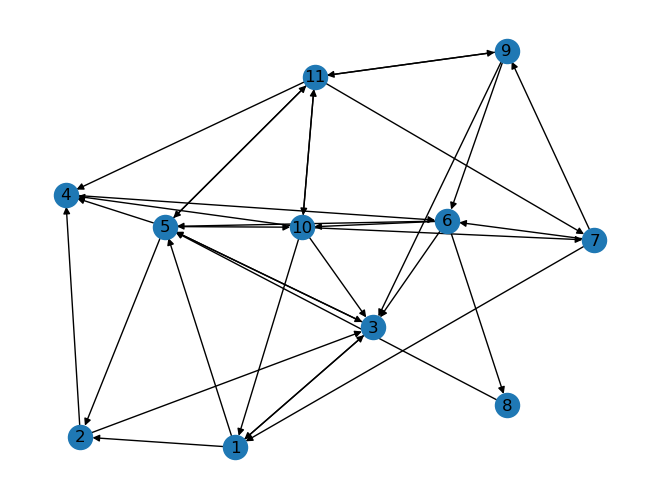

In [88]:
graph1.visualize()

In [90]:
graph1.node

{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11}

In [92]:
print(graph1.edge)

[(1, 2), (1, 3), (1, 5), (2, 3), (2, 4), (3, 5), (3, 1), (4, 6), (5, 4), (5, 10), (5, 11), (5, 2), (5, 3), (6, 8), (6, 5), (6, 3), (6, 10), (7, 6), (7, 9), (7, 1), (8, 5), (9, 11), (9, 3), (9, 6), (10, 1), (10, 11), (10, 7), (10, 4), (10, 3), (11, 10), (11, 9), (11, 7), (11, 5), (11, 4)]


In [94]:
graph1.adjacency

{1: [2, 3, 5],
 2: [3, 4],
 3: [5, 1],
 4: [6],
 5: [4, 10, 11, 2, 3],
 6: [8, 5, 3, 10],
 7: [6, 9, 1],
 8: [5],
 9: [11, 3, 6],
 10: [1, 11, 7, 4, 3],
 11: [10, 9, 7, 5, 4]}

In [96]:
graph1.add_one_edge(100,101)
print(graph1.edge)

[(1, 2), (1, 3), (1, 5), (2, 3), (2, 4), (3, 5), (3, 1), (4, 6), (5, 4), (5, 10), (5, 11), (5, 2), (5, 3), (6, 8), (6, 5), (6, 3), (6, 10), (7, 6), (7, 9), (7, 1), (8, 5), (9, 11), (9, 3), (9, 6), (10, 1), (10, 11), (10, 7), (10, 4), (10, 3), (11, 10), (11, 9), (11, 7), (11, 5), (11, 4), (100, 101)]


In [98]:
graph1.add_one_node(100)
graph1.node

{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 100, 101}

In [100]:
graph1.number_of_users()

' number of users:13'

In [102]:
graph1.number_of_connections()

' number of connections 35'

In [104]:
graph1.neighbors(9)

[11, 3, 6]

In [106]:
graph1.direct_connection(1,2)

True

In [108]:
graph1.bfs(1)

 traversed_graph:[1]
left_el neighbors {2: 1, 3: 1, 5: 1}

 our visited nodes: {1, 2, 3, 5}


 our queue: [2, 3, 5]

 traversed_graph:[1, 2]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2}

 our visited nodes: {1, 2, 3, 4, 5}


 our queue: [3, 5, 4]

 traversed_graph:[1, 2, 3]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2}

 our visited nodes: {1, 2, 3, 4, 5}


 our queue: [5, 4]

 traversed_graph:[1, 2, 3, 5]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 10: 5, 11: 5}

 our visited nodes: {1, 2, 3, 4, 5, 10, 11}


 our queue: [4, 10, 11]

 traversed_graph:[1, 2, 3, 5, 4]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 10: 5, 11: 5, 6: 4}

 our visited nodes: {1, 2, 3, 4, 5, 6, 10, 11}


 our queue: [10, 11, 6]

 traversed_graph:[1, 2, 3, 5, 4, 10]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 10: 5, 11: 5, 6: 4, 7: 10}

 our visited nodes: {1, 2, 3, 4, 5, 6, 7, 10, 11}


 our queue: [11, 6, 7]

 traversed_graph:[1, 2, 3, 5, 4, 10, 11]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 10: 5, 11: 5, 6: 4, 7: 10, 

{2: 1, 3: 1, 5: 1, 4: 2, 10: 5, 11: 5, 6: 4, 7: 10, 9: 11, 8: 6}

In [110]:
graph1.dfs(1)

visited : {1}
Traversed graph : [1]
stack[5, 3, 2]
visited : {1, 2}
Traversed graph : [1, 2]
stack[5, 3, 4, 3]
visited : {1, 2, 3}
Traversed graph : [1, 2, 3]
stack[5, 3, 4, 5]
visited : {1, 2, 3, 5}
Traversed graph : [1, 2, 3, 5]
stack[5, 3, 4, 11, 10, 4]
visited : {1, 2, 3, 4, 5}
Traversed graph : [1, 2, 3, 5, 4]
stack[5, 3, 4, 11, 10, 6]
visited : {1, 2, 3, 4, 5, 6}
Traversed graph : [1, 2, 3, 5, 4, 6]
stack[5, 3, 4, 11, 10, 10, 8]
visited : {1, 2, 3, 4, 5, 6, 8}
Traversed graph : [1, 2, 3, 5, 4, 6, 8]
stack[5, 3, 4, 11, 10, 10]
visited : {1, 2, 3, 4, 5, 6, 8, 10}
Traversed graph : [1, 2, 3, 5, 4, 6, 8, 10]
stack[5, 3, 4, 11, 10, 7, 11]
visited : {1, 2, 3, 4, 5, 6, 8, 10, 11}
Traversed graph : [1, 2, 3, 5, 4, 6, 8, 10, 11]
stack[5, 3, 4, 11, 10, 7, 7, 9]
visited : {1, 2, 3, 4, 5, 6, 8, 9, 10, 11}
Traversed graph : [1, 2, 3, 5, 4, 6, 8, 10, 11, 9]
stack[5, 3, 4, 11, 10, 7, 7]
visited : {1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11}
Traversed graph : [1, 2, 3, 5, 4, 6, 8, 10, 11, 9, 7]
stack[5, 

In [112]:
graph1.shortest_path(1,9)

 traversed_graph:[1]
left_el neighbors {2: 1, 3: 1, 5: 1}

 our visited nodes: {1, 2, 3, 5}


 our queue: [2, 3, 5]

 traversed_graph:[1, 2]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2}

 our visited nodes: {1, 2, 3, 4, 5}


 our queue: [3, 5, 4]

 traversed_graph:[1, 2, 3]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2}

 our visited nodes: {1, 2, 3, 4, 5}


 our queue: [5, 4]

 traversed_graph:[1, 2, 3, 5]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 10: 5, 11: 5}

 our visited nodes: {1, 2, 3, 4, 5, 10, 11}


 our queue: [4, 10, 11]

 traversed_graph:[1, 2, 3, 5, 4]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 10: 5, 11: 5, 6: 4}

 our visited nodes: {1, 2, 3, 4, 5, 6, 10, 11}


 our queue: [10, 11, 6]

 traversed_graph:[1, 2, 3, 5, 4, 10]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 10: 5, 11: 5, 6: 4, 7: 10}

 our visited nodes: {1, 2, 3, 4, 5, 6, 7, 10, 11}


 our queue: [11, 6, 7]

 traversed_graph:[1, 2, 3, 5, 4, 10, 11]
Our path between 1 and 9 node :
1-->5-->11-->9


BFS: https://www.youtube.com/watch?v=m1_0UlIFnLs

explanation in my yellow notebook.

BFS is used instead of DFS for shortest path because BFS explores the graph level by level, so the first path it finds is the shortest path in an unweighted graph.


Please enter your csv file path : "C:\Users\ALFA\Documents\csv_file_test.csv"


[[1, 2], [1, 3], [1, 5], [2, 3], [2, 4], [3, 6], [5, 7], [5, 8], [7, 8]]

Social Media Communication Graph:

1 -> 2 3 5
2 -> 3 4
3 -> 6
4 -> 
5 -> 7 8
6 -> 
7 -> 8
8 -> 



~~~ Graph Analyzer ~~~
1. Number of users
2. Number of connections
3. Show neighbors
4. BFS
5. DFS
6. Find path
7. Shortest path
8. Visualize
0. Exit
Choose an option: 8


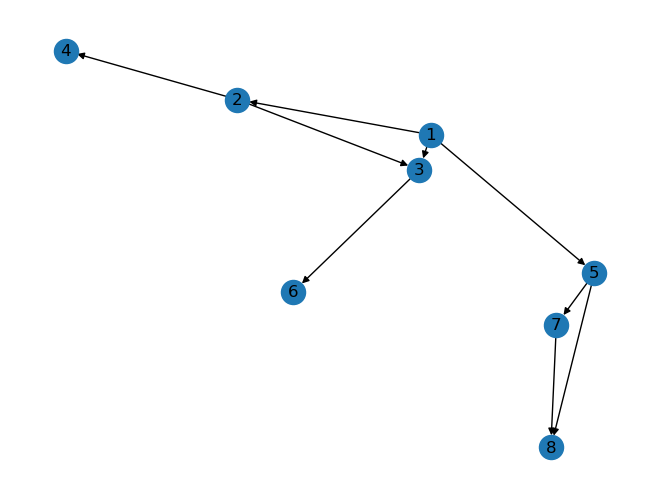


Do you want to continue? yes or no yes

~~~ Graph Analyzer ~~~
1. Number of users
2. Number of connections
3. Show neighbors
4. BFS
5. DFS
6. Find path
7. Shortest path
8. Visualize
0. Exit
Choose an option: 1


 number of users:8



Do you want to continue? yes or no yes

~~~ Graph Analyzer ~~~
1. Number of users
2. Number of connections
3. Show neighbors
4. BFS
5. DFS
6. Find path
7. Shortest path
8. Visualize
0. Exit
Choose an option: 2


 number of connections 9



Do you want to continue? yes or no yes

~~~ Graph Analyzer ~~~
1. Number of users
2. Number of connections
3. Show neighbors
4. BFS
5. DFS
6. Find path
7. Shortest path
8. Visualize
0. Exit
Choose an option: 3

Enter the node which neighbors you want to identify: 1


[2, 3, 5]


... (5 outputs left out)

 traversed_graph:[1]
left_el neighbors {2: 1, 3: 1, 5: 1}

 our visited nodes: {1, 2, 3, 5}


 our queue: [2, 3, 5]

 traversed_graph:[1, 2]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2}

 our visited nodes: {1, 2, 3, 4, 5}


 our queue: [3, 5, 4]

 traversed_graph:[1, 2, 3]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 6: 3}

 our visited nodes: {1, 2, 3, 4, 5, 6}


 our queue: [5, 4, 6]

 traversed_graph:[1, 2, 3, 5]
Our path between 1 and 8 node :
1-->5-->8



Do you want to continue? yes or no yes

~~~ Graph Analyzer ~~~
1. Number of users
2. Number of connections
3. Show neighbors
4. BFS
5. DFS
6. Find path
7. Shortest path
8. Visualize
0. Exit
Choose an option: 7

Please enter the source node: 1

please enter the target node: 8


 traversed_graph:[1]
left_el neighbors {2: 1, 3: 1, 5: 1}

 our visited nodes: {1, 2, 3, 5}


 our queue: [2, 3, 5]

 traversed_graph:[1, 2]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2}

 our visited nodes: {1, 2, 3, 4, 5}


 our queue: [3, 5, 4]

 traversed_graph:[1, 2, 3]
left_el neighbors {2: 1, 3: 1, 5: 1, 4: 2, 6: 3}

 our visited nodes: {1, 2, 3, 4, 5, 6}


 our queue: [5, 4, 6]

 traversed_graph:[1, 2, 3, 5]
Our path between 1 and 8 node :
1-->5-->8



Do you want to continue? yes or no no


In [117]:
# Run the graph analyzer through a simple command-line menu

# Get the CSV file path from the user
Graph_file = input('\nPlease enter your csv file path :').strip().strip("'\"")
test_edges = csv_file(Graph_file)
print(test_edges)

# Build the graph from the CSV data
graph = Graph()
graph.add_node_list(test_edges)
graph.build_edges(test_edges)
graph.add_adjacency_list(test_edges)

# Run the graph analyzer through a simple command-line menu
a = True
while a:
    graph_analyzer = input("\n~~~ Graph Analyzer ~~~\n1. Number of users\n2. Number of connections\n3. Show neighbors\n4. BFS\n5. DFS\n6. Find path\n7. Shortest path\n8. Visualize\n0. Exit\nChoose an option:").lower()

    if graph_analyzer == '1' or graph_analyzer =='number of users':
        print(graph.number_of_users())
        
    elif graph_analyzer == '2' or graph_analyzer == 'number of connections':
        print(graph.number_of_connections())
        
    elif graph_analyzer =='3' or graph_analyzer == 'show neighbors':
        node = int(input('\nEnter the node which neighbors you want to identify:'))
        print(graph.neighbors(node))
        
    elif graph_analyzer == '4' or graph_analyzer == 'bfs':
        node = int(input('\nFor which node do you want to obtain the BFS result?'))
        graph.bfs(node)
        
    elif graph_analyzer == '5' or graph_analyzer == 'dfs':
        node = int(input('\nFor which node do you want to obtain the dfs result?'))
        graph.dfs(node)
        
    elif graph_analyzer == '6' or graph_analyzer == 'find path' or graph_analyzer == '7' or graph_analyzer == 'shortest path':
        source = int(input('\nPlease enter the source node:'))
        target = int (input('\nplease enter the target node:'))
        graph.find_path(source,target)
    
    elif graph_analyzer == '7' or graph_analyzer == 'shortest path':
        source = int(input('\nPlease enter the source node:'))
        target = int(input('\nPlease enter the target node:'))
        graph.shortest_path(source, target)
        
    elif graph_analyzer == '8' or graph_analyzer == 'visualize':
        graph.visualize()
        
    elif graph_analyzer =='0' or graph_analyzer =='exit':
        a = False
        
    else: 
        print('\nPlease enter correct number or correct spelling and if you want to exit please enter 0')

    continue_graph = input('\nDo you want to continue? yes or no').lower()
    if continue_graph =='yes'or continue_graph == 'y':
        a = True
    else:
        a = False
        
    